In [ ]:
!pip install openpyxl

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

In [ ]:
uploaded = files.upload()

Saving Dataset for Data Analytics (1).xlsx to Dataset for Data Analytics (1) (1).xlsx


In [ ]:
filename = list(uploaded.keys())[0]

df = pd.read_excel(filename)

df.head()

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   OrderID          1200 non-null   object        
 1   Date             1200 non-null   datetime64[ns]
 2   CustomerID       1200 non-null   object        
 3   Product          1200 non-null   object        
 4   Quantity         1200 non-null   int64         
 5   UnitPrice        1200 non-null   float64       
 6   ShippingAddress  1200 non-null   object        
 7   PaymentMethod    1200 non-null   object        
 8   OrderStatus      1200 non-null   object        
 9   TrackingNumber   1200 non-null   object        
 10  ItemsInCart      1200 non-null   int64         
 11  CouponCode       891 non-null    object        
 12  ReferralSource   1200 non-null   object        
 13  TotalPrice       1200 non-null   float64       
dtypes: datetime64[ns](1), float64(2), int64(

In [ ]:
print(df.shape)

(1200, 14)


In [ ]:
print(df.columns)

Index(['OrderID', 'Date', 'CustomerID', 'Product', 'Quantity', 'UnitPrice',
       'ShippingAddress', 'PaymentMethod', 'OrderStatus', 'TrackingNumber',
       'ItemsInCart', 'CouponCode', 'ReferralSource', 'TotalPrice'],
      dtype='object')


In [ ]:
df.isnull().sum()

,0
OrderID,0
Date,0
CustomerID,0
Product,0
Quantity,0
UnitPrice,0
ShippingAddress,0
PaymentMethod,0
OrderStatus,0
TrackingNumber,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,Date,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200,1200.000000,1200.000000,1200.000000,1200.000000
mean,2024-03-22 16:58:48,2.945833,356.412750,5.485000,1053.968300
min,2023-01-01 00:00:00,1.000000,11.390000,1.000000,11.390000
25%,2023-08-03 18:00:00,2.000000,186.062500,4.000000,410.520000
50%,2024-03-23 00:00:00,3.000000,364.210000,5.000000,823.615000
75%,2024-11-08 12:00:00,4.000000,521.570000,7.000000,1578.475000
max,2025-06-30 00:00:00,5.000000,699.930000,10.000000,3456.400000
std,NaN,1.407557,197.177146,2.281983,819.856558


In [ ]:
df.mean(numeric_only=True)

,0
Quantity,2.945833
UnitPrice,356.412750
ItemsInCart,5.485000
TotalPrice,1053.968300


In [ ]:
df.median(numeric_only=True)

,0
Quantity,3.000
UnitPrice,364.210
ItemsInCart,5.000
TotalPrice,823.615


In [ ]:
df.max(numeric_only=True)

,0
Quantity,5.00
UnitPrice,699.93
ItemsInCart,10.00
TotalPrice,3456.40


In [ ]:
df.min(numeric_only=True)

,0
Quantity,1.00
UnitPrice,11.39
ItemsInCart,1.00
TotalPrice,11.39


In [ ]:
df.count()

,0
OrderID,1200
Date,1200
CustomerID,1200
Product,1200
Quantity,1200
UnitPrice,1200
ShippingAddress,1200
PaymentMethod,1200
OrderStatus,1200
TrackingNumber,1200


In [ ]:
df.corr(numeric_only=True)

,Quantity,UnitPrice,ItemsInCart,TotalPrice
Quantity,1.000000,0.014553,0.650061,0.615251
UnitPrice,0.014553,1.000000,0.000602,0.717081
ItemsInCart,0.650061,0.000602,1.000000,0.392540
TotalPrice,0.615251,0.717081,0.392540,1.000000


In [ ]:
numeric_columns = df.select_dtypes(include=np.number).columns

for col in numeric_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, ":", len(outliers))

Quantity : 0
UnitPrice : 0
ItemsInCart : 0
TotalPrice : 8


In [ ]:
df.groupby("Product")["TotalPrice"].sum()

,TotalPrice
Product,
Chair,195620.11
Desk,167459.93
Laptop,192126.56
Monitor,175651.41
Phone,151722.39
Printer,195612.61
Tablet,186568.95


In [ ]:
df["PaymentMethod"].value_counts()

,count
PaymentMethod,
Online,258
Cash,246
Credit Card,234
Debit Card,232
Gift Card,230


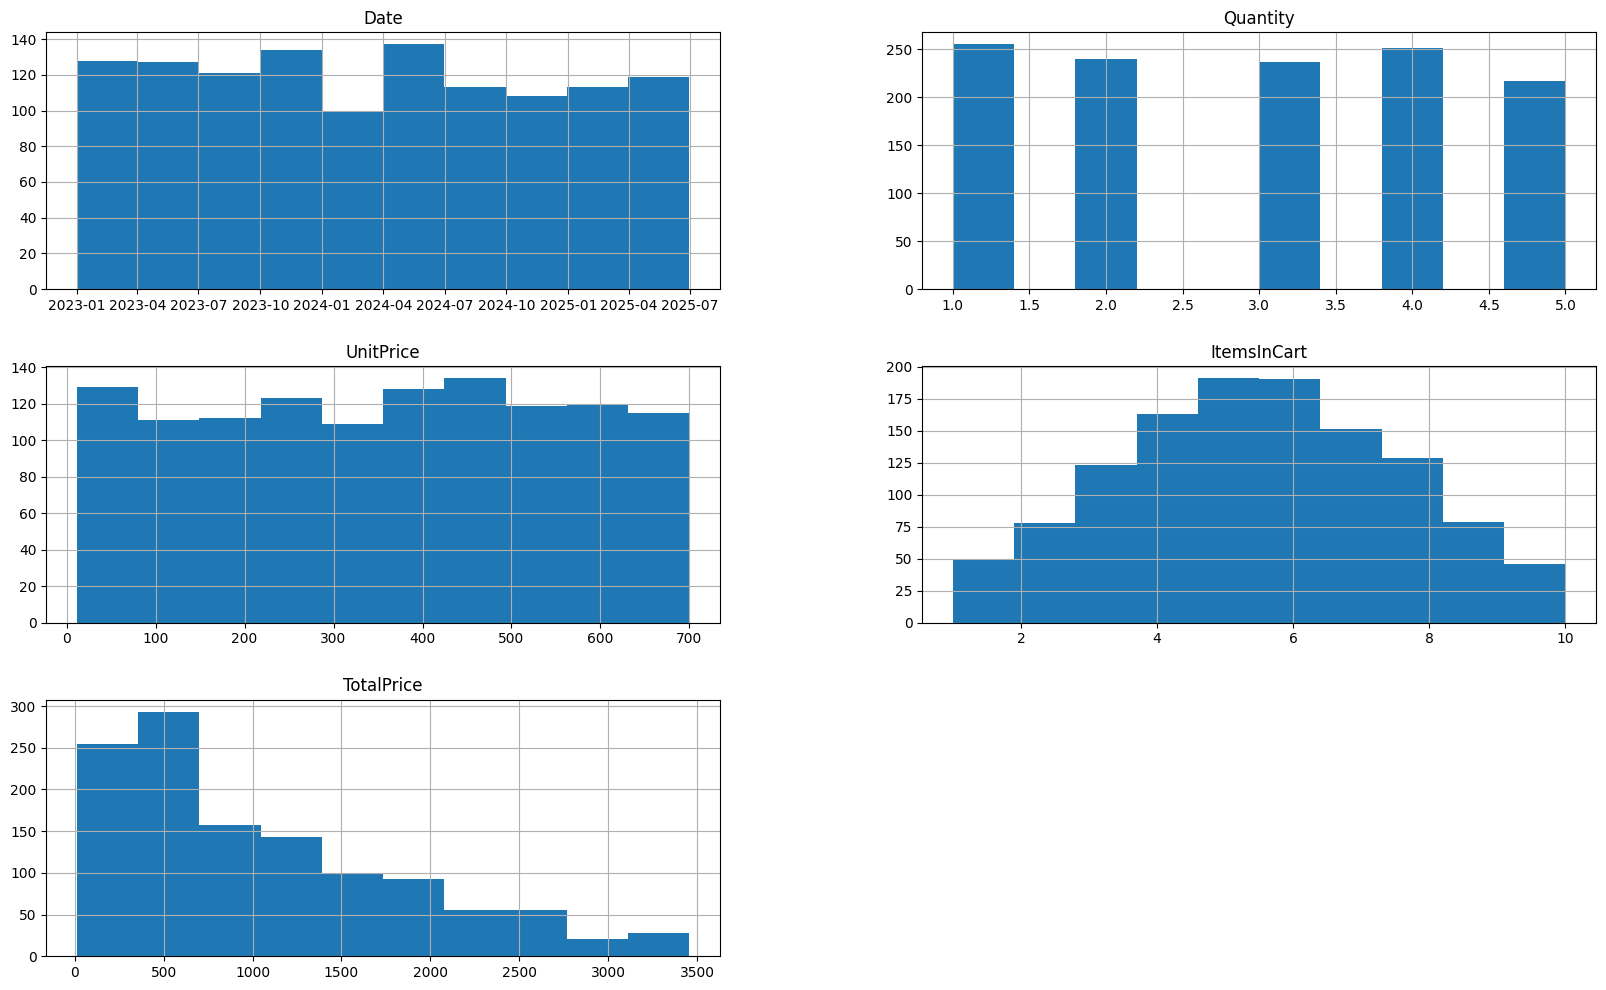

In [ ]:
df.hist(figsize=(20,12))
plt.show()

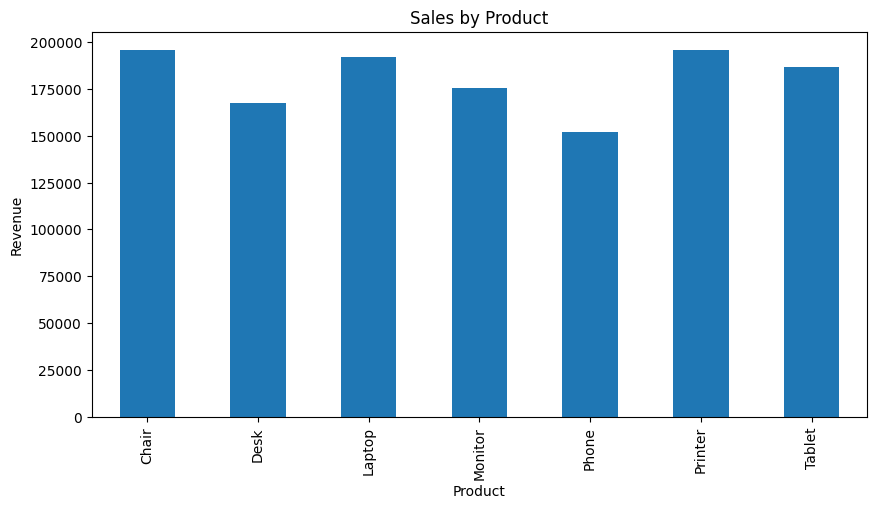

In [ ]:
product_sales = df.groupby("Product")["TotalPrice"].sum()

product_sales.plot(kind="bar", figsize=(10,5))

plt.title("Sales by Product")
plt.xlabel("Product")
plt.ylabel("Revenue")

plt.show()

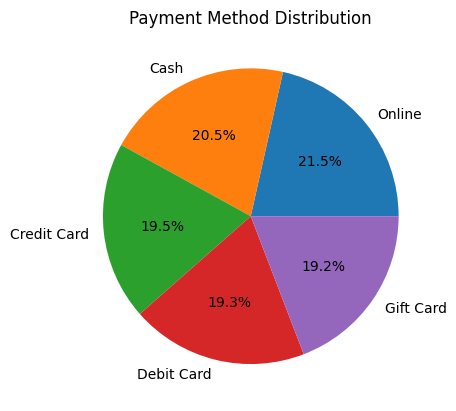

In [ ]:
df["PaymentMethod"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.title("Payment Method Distribution")
plt.ylabel("")
plt.show()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

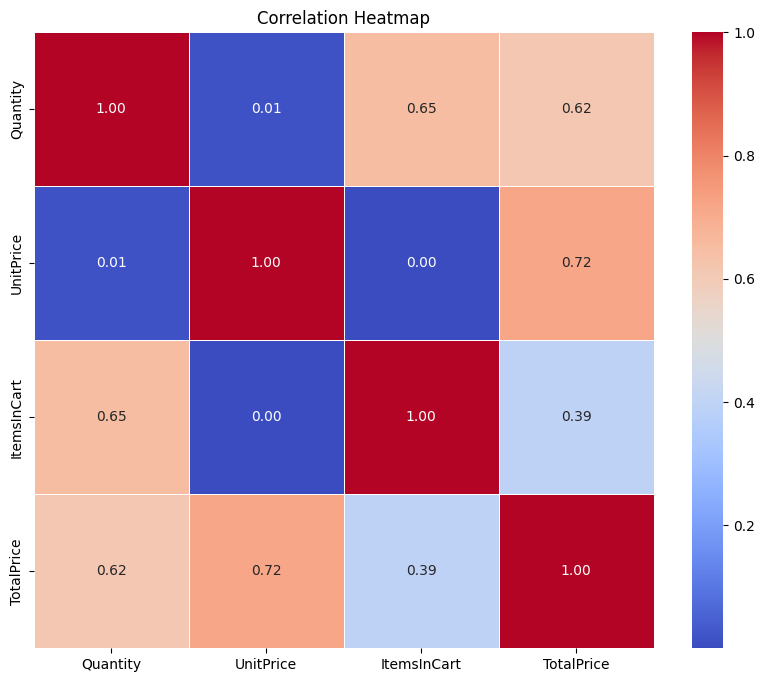

In [ ]:
correlation = df.corr(numeric_only=True)

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()